# Boosted trees

Same target, same day-ahead features, and the same last-28-days holdout as the linear notebook.

A tree is the model class that fits the correlation structure. Once the hour-of-day mean is removed, demand still moves with carbon, and temperature's link shows up only after that removal. Radiation's remaining link is smaller. Those are interactions with the hour: weather should be allowed to matter in some hours and not others. Hour and weekday are passed in as categories so that hour 23 is not treated as a larger number than hour 0.

The search is learning rate, tree depth, and the minimum samples in a leaf. Loss stays absolute error, so the search is aimed at MAE. Squared error and quantile loss are compared on their own in the loss notebook, with the tree size held still. A neural net is not in this search: a few thousand aligned hourly rows with a dominant clock do not need one.

The selected tree is the one with the lowest forward-validation MAE. Test numbers are reported after that choice.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from src.modeling import (
    DAY_AHEAD_CATEGORICAL,
    DAY_AHEAD_NUMERIC,
    feature_matrix,
    make_tree,
    search_time_series,
)

from src.carbon_data import load_model_frame
from src.modeling import TARGET, hour_climatology, result_row, score_predictions, train_test_split

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
baseline = hour_climatology(train, test)
baseline_mae = score_predictions(test[TARGET], baseline)["mae"]
print(f"{len(frame)} hours, {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d} UTC")
print(
    f"train {len(train)} hours through {train.index.max():%Y-%m-%d %H} UTC; "
    f"test {len(test)} hours from {test.index.min():%Y-%m-%d %H} UTC"
)
print(f"hour-of-day baseline MAE on the test block: {baseline_mae:.2f} g/kWh")


6793 hours, 2026-01-08 to 2026-10-18 UTC
train 6120 hours through 2026-09-20 22 UTC; test 673 hours from 2026-09-20 23 UTC
hour-of-day baseline MAE on the test block: 70.62 g/kWh


## Search

Twelve settings: two learning rates, three depths (`None` means no depth limit), two leaf sizes. Each one is scored on four forward folds. `max_iter` stays at 300.

In [2]:
x_train = feature_matrix(train, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC)
x_test = feature_matrix(test, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC)
assert list(x_train.columns[:2]) == ["hour_local", "dow"]

tree = make_tree(loss="absolute_error")
tree.set_params(categorical_features=[0, 1])
search = search_time_series(
    tree,
    {
        "learning_rate": [0.05, 0.1],
        "max_depth": [3, 6, None],
        "min_samples_leaf": [20, 80],
    },
    x_train,
    train[TARGET],
)

fold_results = pd.DataFrame(search.cv_results_)
fold_results["cv_mae"] = -fold_results["mean_test_score"]
fold_results["depth"] = fold_results["param_max_depth"].map(lambda value: "none" if value is None else str(value))
fold_results = fold_results.rename(
    columns={
        "param_learning_rate": "learning_rate",
        "param_min_samples_leaf": "min_samples_leaf",
    }
)
view = fold_results[["learning_rate", "depth", "min_samples_leaf", "cv_mae"]].sort_values("cv_mae")
print(
    "Selected on forward validation: "
    f"learning_rate={search.best_params_['learning_rate']:g}, "
    f"max_depth={search.best_params_['max_depth']}, "
    f"min_samples_leaf={search.best_params_['min_samples_leaf']}"
)
view.round(3)


Selected on forward validation: learning_rate=0.05, max_depth=3, min_samples_leaf=80


,learning_rate,depth,min_samples_leaf,cv_mae
1,0.05,3,80,26.281
4,0.05,none,20,26.820
5,0.05,none,80,27.376
7,0.10,3,80,27.554
3,0.05,6,80,27.936
10,0.10,none,20,28.073
2,0.05,6,20,28.165
11,0.10,none,80,28.172
0,0.05,3,20,28.529
8,0.10,6,20,28.585


Test MAE 26.40 g/kWh, 62.6% below the hour-of-day mean (70.62 g/kWh).


/var/folders/g2/mv6w8l9x5412btq20l7_rg3w0000gn/T/ipykernel_59259/2047093713.py:34: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()


,model,mae,rmse,cv_mae,skill_vs_hour,detail
0,hour-of-day mean,70.622,83.744,NaN,0.000,NaN
1,selected tree,26.396,32.147,26.281,0.626,"lr=0.05, depth=3, leaf=80"


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/events.py:82: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


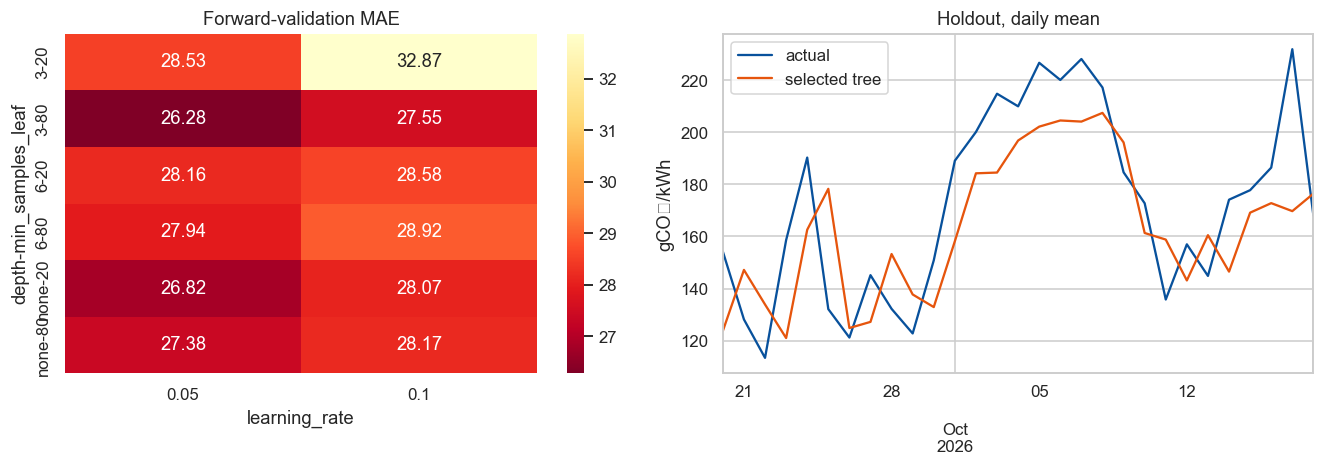

In [3]:
predicted = search.predict(x_test)
detail = (
    f"lr={search.best_params_['learning_rate']:g}, "
    f"depth={search.best_params_['max_depth']}, "
    f"leaf={search.best_params_['min_samples_leaf']}"
)
holdout = pd.DataFrame(
    [
        result_row("hour-of-day mean", test[TARGET], baseline, float("nan"), baseline_mae),
        result_row("selected tree", test[TARGET], predicted, -search.best_score_, baseline_mae)
        | {"detail": detail},
    ]
)
winner = holdout.dropna(subset=["cv_mae"]).iloc[0]
print(
    f"Test MAE {winner['mae']:.2f} g/kWh, "
    f"{100 * winner['skill_vs_hour']:.1f}% below the hour-of-day mean "
    f"({baseline_mae:.2f} g/kWh)."
)
display_table = holdout.round(3)

pivot = view.pivot_table(index=["depth", "min_samples_leaf"], columns="learning_rate", values="cv_mae")
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="YlOrRd_r", ax=axes[0])
axes[0].set_title("Forward-validation MAE")
daily = pd.DataFrame(
    {"actual": test[TARGET].to_numpy(), "selected tree": predicted},
    index=test.index.tz_convert("America/Los_Angeles"),
).resample("D").mean()
daily.plot(ax=axes[1], color=["#08519c", "#e6550d"])
axes[1].set_ylabel("gCO₂/kWh")
axes[1].set_title("Holdout, daily mean")
axes[1].set_xlabel("")
fig.tight_layout()
display_table
